# 3. Model Training
## Testing All Feature × Model Combinations (6 total)
### Training on Train Set, Evaluating on Validation Set

In [1]:
import sys
sys.path.append('..')

import joblib
import pandas as pd
import matplotlib.pyplot as plt
from src.models.baseline import BaselineModels
from src.models.traditional_ml import TraditionalMLModels
from src.evaluation import ModelEvaluator
from src.utils import save_model

import warnings
warnings.filterwarnings('ignore')

%matplotlib inline

## Load All Features (Train + Validation)

In [2]:
# Load TF-IDF features
X_train_tfidf = joblib.load('../data/processed/X_train_tfidf.pkl')
X_val_tfidf = joblib.load('../data/processed/X_val_tfidf.pkl')

# Load Bag of Words features
X_train_bow = joblib.load('../data/processed/X_train_count.pkl')
X_val_bow = joblib.load('../data/processed/X_val_count.pkl')

# Load labels
y_train = joblib.load('../data/processed/y_train.pkl')
y_val = joblib.load('../data/processed/y_val.pkl')

print(f"TF-IDF - Train: {X_train_tfidf.shape}, Val: {X_val_tfidf.shape}")
print(f"BoW    - Train: {X_train_bow.shape}, Val: {X_val_bow.shape}")
print(f"Labels - Train: {y_train.shape}, Val: {y_val.shape}")

TF-IDF - Train: (102000, 5000), Val: (18000, 5000)
BoW    - Train: (102000, 5000), Val: (18000, 5000)
Labels - Train: (102000,), Val: (18000,)


## Initialize Evaluator

In [3]:
evaluator = ModelEvaluator()

## Test All Combinations
### 2 Features × 3 Models = 6 Experiments
### Training on 85% of data, Evaluating on 15% validation set

In [4]:
# Define features and models to test
features = {
    'BoW': (X_train_bow, X_val_bow),
    'TF-IDF': (X_train_tfidf, X_val_tfidf)
}

models_config = {
    'Naive Bayes': BaselineModels.get_naive_bayes(),
    'Logistic Regression': BaselineModels.get_logistic_regression(),
    'Linear SVM': TraditionalMLModels.get_svm()
}

# Store all results
all_results = []

# Test all combinations
for feature_name, (X_train, X_val) in features.items():
    print(f"\n{'='*60}")
    print(f"Feature: {feature_name}")
    print('='*60)
    
    for model_name, model in models_config.items():
        print(f"\nTraining {model_name} with {feature_name}...")
        
        # Train on train set, evaluate on validation set
        metrics, predictions = evaluator.train_and_evaluate(
            model, X_train, y_train, X_val, y_val, 
            f"{model_name} ({feature_name})"
        )
        
        # Add feature type to metrics
        metrics['feature_type'] = feature_name
        metrics['model_only'] = model_name
        
        all_results.append(metrics)
        
        # Print results
        print(f"  Accuracy: {metrics['accuracy']:.4f}")
        print(f"  F1-Score (Macro): {metrics['f1_macro']:.4f}")
        print(f"  F1-Score (Weighted): {metrics['f1_weighted']:.4f}")
        print(f"  Train Time: {metrics['train_time']:.2f}s")
        
        # Save model
        model_filename = f"../models/{model_name.lower().replace(' ', '_')}_{feature_name.lower().replace('-', '')}.pkl"
        save_model(model, model_filename)

print(f"\n{'='*60}")
print("All 6 combinations trained successfully!")
print('='*60)


Feature: BoW

Training Naive Bayes with BoW...
  Accuracy: 0.8987
  F1-Score (Macro): 0.8984
  F1-Score (Weighted): 0.8984
  Train Time: 0.02s
Model saved to ../models/naive_bayes_bow.pkl

Training Logistic Regression with BoW...
  Accuracy: 0.9028
  F1-Score (Macro): 0.9026
  F1-Score (Weighted): 0.9026
  Train Time: 1.90s
Model saved to ../models/logistic_regression_bow.pkl

Training Linear SVM with BoW...
  Accuracy: 0.9040
  F1-Score (Macro): 0.9038
  F1-Score (Weighted): 0.9038
  Train Time: 7.17s
Model saved to ../models/linear_svm_bow.pkl

Feature: TF-IDF

Training Naive Bayes with TF-IDF...
  Accuracy: 0.8990
  F1-Score (Macro): 0.8987
  F1-Score (Weighted): 0.8987
  Train Time: 0.01s
Model saved to ../models/naive_bayes_tfidf.pkl

Training Logistic Regression with TF-IDF...
  Accuracy: 0.9127
  F1-Score (Macro): 0.9125
  F1-Score (Weighted): 0.9125
  Train Time: 1.89s
Model saved to ../models/logistic_regression_tfidf.pkl

Training Linear SVM with TF-IDF...
  Accuracy: 0.9138

## Detailed Metrics and Confusion Matrices
### Evaluated on Validation Set


Naive Bayes (BoW)

Metrics (on Validation Set):
  Accuracy:              0.8987
  Precision (Macro):     0.8983
  Recall (Macro):        0.8987
  F1-Score (Macro):      0.8984
  F1-Score (Weighted):   0.8984
  Training Time:         0.02s

Per-Class Metrics:
              precision    recall  f1-score   support

       World       0.91      0.89      0.90      4500
      Sports       0.94      0.97      0.96      4500
    Business       0.88      0.86      0.87      4500
    Sci/Tech       0.87      0.87      0.87      4500

    accuracy                           0.90     18000
   macro avg       0.90      0.90      0.90     18000
weighted avg       0.90      0.90      0.90     18000



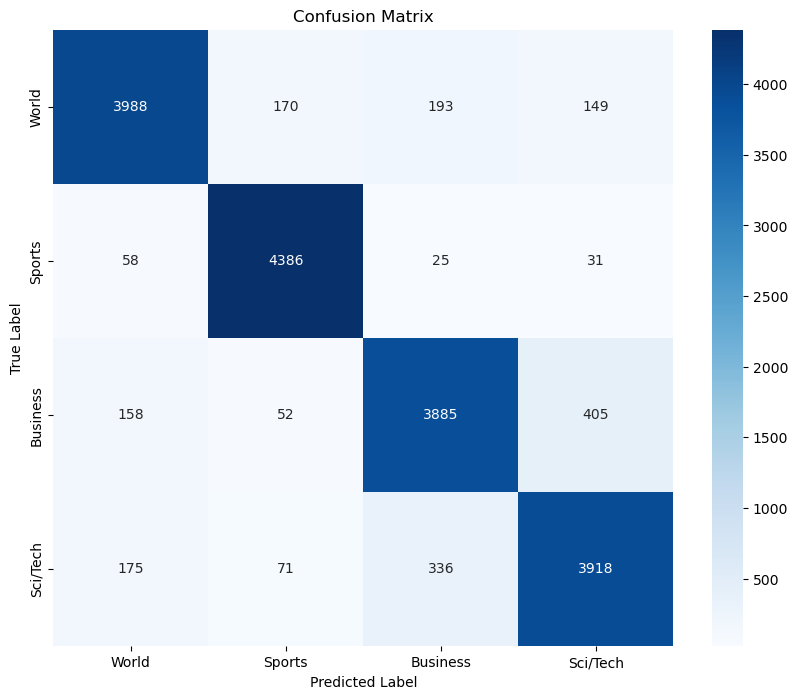


Logistic Regression (BoW)

Metrics (on Validation Set):
  Accuracy:              0.9028
  Precision (Macro):     0.9026
  Recall (Macro):        0.9028
  F1-Score (Macro):      0.9026
  F1-Score (Weighted):   0.9026
  Training Time:         1.90s

Per-Class Metrics:
              precision    recall  f1-score   support

       World       0.91      0.89      0.90      4500
      Sports       0.94      0.97      0.95      4500
    Business       0.87      0.87      0.87      4500
    Sci/Tech       0.88      0.88      0.88      4500

    accuracy                           0.90     18000
   macro avg       0.90      0.90      0.90     18000
weighted avg       0.90      0.90      0.90     18000



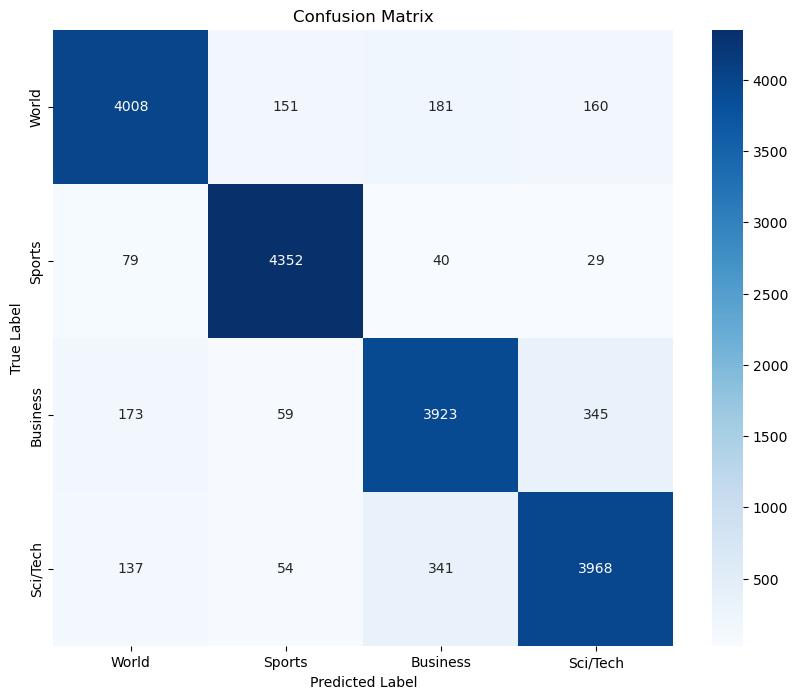


Linear SVM (BoW)

Metrics (on Validation Set):
  Accuracy:              0.9040
  Precision (Macro):     0.9039
  Recall (Macro):        0.9040
  F1-Score (Macro):      0.9038
  F1-Score (Weighted):   0.9038
  Training Time:         7.17s

Per-Class Metrics:
              precision    recall  f1-score   support

       World       0.92      0.89      0.90      4500
      Sports       0.94      0.97      0.95      4500
    Business       0.88      0.88      0.88      4500
    Sci/Tech       0.88      0.88      0.88      4500

    accuracy                           0.90     18000
   macro avg       0.90      0.90      0.90     18000
weighted avg       0.90      0.90      0.90     18000



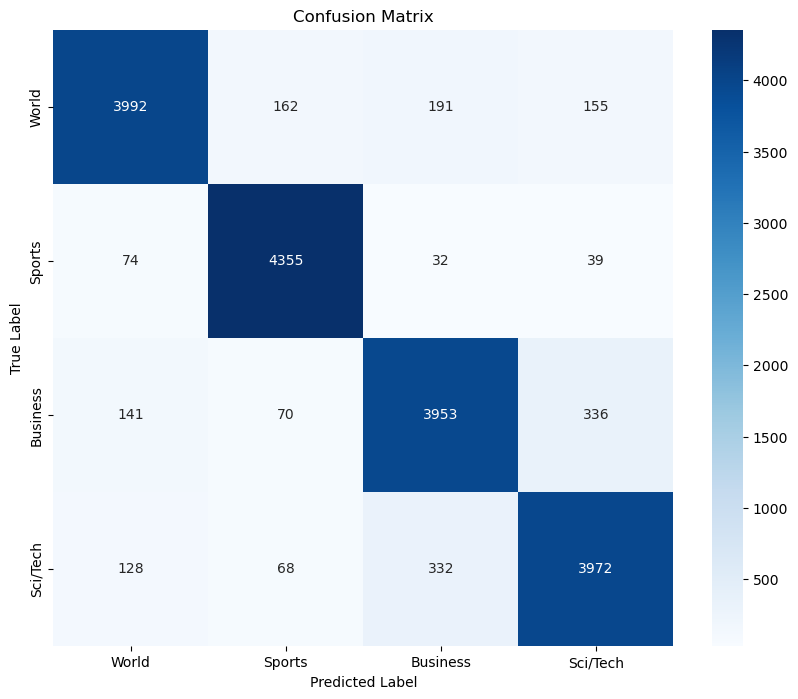


Naive Bayes (TF-IDF)

Metrics (on Validation Set):
  Accuracy:              0.8990
  Precision (Macro):     0.8987
  Recall (Macro):        0.8990
  F1-Score (Macro):      0.8987
  F1-Score (Weighted):   0.8987
  Training Time:         0.01s

Per-Class Metrics:
              precision    recall  f1-score   support

       World       0.91      0.88      0.90      4500
      Sports       0.94      0.97      0.96      4500
    Business       0.87      0.87      0.87      4500
    Sci/Tech       0.87      0.87      0.87      4500

    accuracy                           0.90     18000
   macro avg       0.90      0.90      0.90     18000
weighted avg       0.90      0.90      0.90     18000



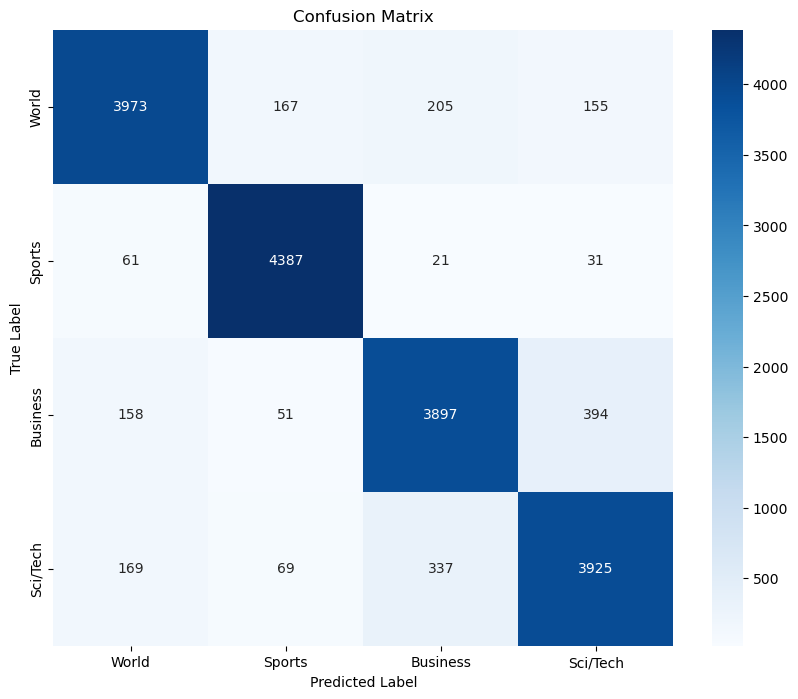


Logistic Regression (TF-IDF)

Metrics (on Validation Set):
  Accuracy:              0.9127
  Precision (Macro):     0.9126
  Recall (Macro):        0.9127
  F1-Score (Macro):      0.9125
  F1-Score (Weighted):   0.9125
  Training Time:         1.89s

Per-Class Metrics:
              precision    recall  f1-score   support

       World       0.93      0.90      0.91      4500
      Sports       0.95      0.98      0.96      4500
    Business       0.88      0.89      0.89      4500
    Sci/Tech       0.89      0.89      0.89      4500

    accuracy                           0.91     18000
   macro avg       0.91      0.91      0.91     18000
weighted avg       0.91      0.91      0.91     18000



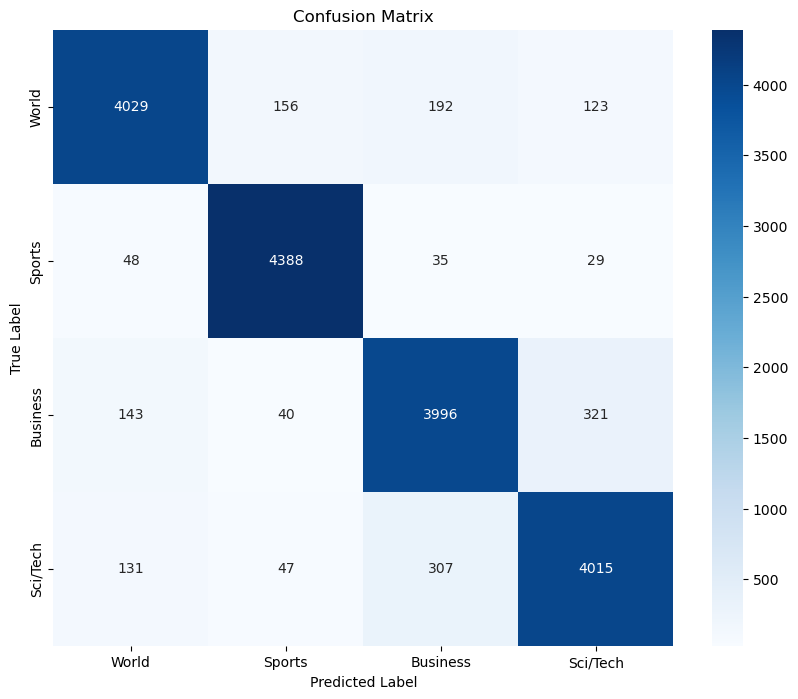


Linear SVM (TF-IDF)

Metrics (on Validation Set):
  Accuracy:              0.9138
  Precision (Macro):     0.9137
  Recall (Macro):        0.9138
  F1-Score (Macro):      0.9136
  F1-Score (Weighted):   0.9136
  Training Time:         2.79s

Per-Class Metrics:
              precision    recall  f1-score   support

       World       0.93      0.89      0.91      4500
      Sports       0.95      0.98      0.96      4500
    Business       0.88      0.89      0.89      4500
    Sci/Tech       0.90      0.89      0.89      4500

    accuracy                           0.91     18000
   macro avg       0.91      0.91      0.91     18000
weighted avg       0.91      0.91      0.91     18000



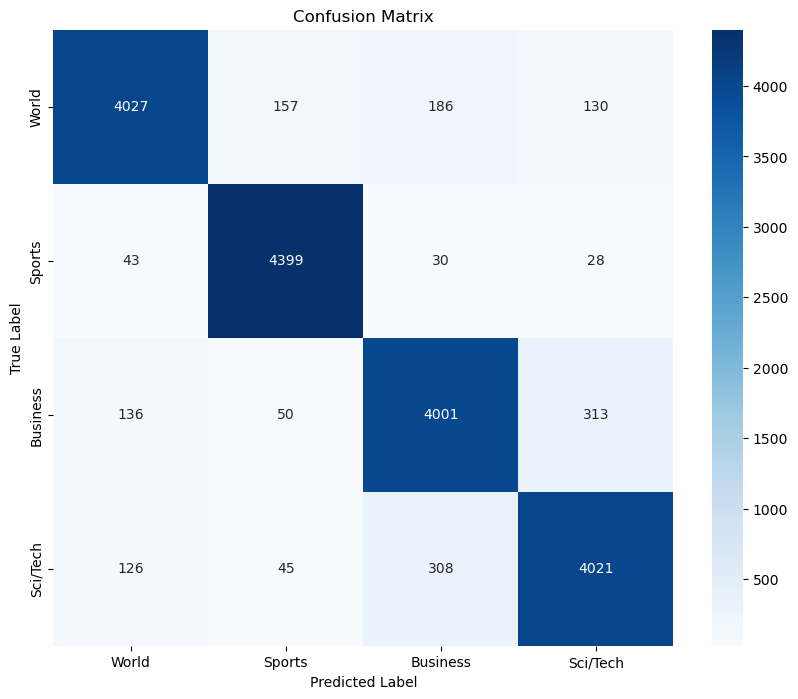

In [5]:
# For each combination, show detailed metrics and confusion matrix
for i, result in enumerate(all_results):
    print(f"\n{'='*60}")
    print(f"{result['model_name']}")
    print('='*60)
    
    # Load the saved model
    feature_suffix = result['feature_type'].lower().replace('-', '')
    model_filename = f"../models/{result['model_only'].lower().replace(' ', '_')}_{feature_suffix}.pkl"
    model = joblib.load(model_filename)
    
    # Get predictions on validation set
    if result['feature_type'] == 'BoW':
        y_pred = model.predict(X_val_bow)
    else:
        y_pred = model.predict(X_val_tfidf)
    
    # Print detailed metrics
    print(f"\nMetrics (on Validation Set):")
    print(f"  Accuracy:              {result['accuracy']:.4f}")
    print(f"  Precision (Macro):     {result['precision_macro']:.4f}")
    print(f"  Recall (Macro):        {result['recall_macro']:.4f}")
    print(f"  F1-Score (Macro):      {result['f1_macro']:.4f}")
    print(f"  F1-Score (Weighted):   {result['f1_weighted']:.4f}")
    print(f"  Training Time:         {result['train_time']:.2f}s")
    
    # Print classification report
    print(f"\nPer-Class Metrics:")
    evaluator.print_classification_report(y_val, y_pred)
    
    # Plot confusion matrix
    save_path = f"../results/figures/confusion_matrix_{result['model_only'].lower().replace(' ', '_')}_{feature_suffix}.png"
    evaluator.plot_confusion_matrix(y_val, y_pred, save_path=save_path)
    plt.show()

## Results Comparison Table

In [6]:
# Create results dataframe
results_df = pd.DataFrame(all_results)

# Reorder columns for better readability
column_order = ['model_name', 'feature_type', 'model_only', 'accuracy', 
                'precision_macro', 'recall_macro', 'f1_macro', 'f1_weighted',
                'train_time', 'predict_time']
results_df = results_df[column_order]

# Save full results
results_df.to_csv('../results/comparison.csv', index=False)

print("\nFull Results Table (Validation Set):")
print(results_df.to_string())


Full Results Table (Validation Set):
                     model_name feature_type           model_only  accuracy  precision_macro  recall_macro  f1_macro  f1_weighted  train_time  predict_time
0             Naive Bayes (BoW)          BoW          Naive Bayes  0.898722         0.898343      0.898722  0.898390     0.898390    0.018493      0.003040
1     Logistic Regression (BoW)          BoW  Logistic Regression  0.902833         0.902604      0.902833  0.902649     0.902649    1.897144      0.002570
2              Linear SVM (BoW)          BoW           Linear SVM  0.904000         0.903897      0.904000  0.903802     0.903802    7.167559      0.002000
3          Naive Bayes (TF-IDF)       TF-IDF          Naive Bayes  0.899000         0.898662      0.899000  0.898685     0.898685    0.014270      0.002007
4  Logistic Regression (TF-IDF)       TF-IDF  Logistic Regression  0.912667         0.912562      0.912667  0.912498     0.912498    1.888744      0.000998
5           Linear SVM (TF

## Best Model per Feature Type

In [7]:
print("\nBest Model for Each Feature Type:")
print("="*60)

for feature_type in ['BoW', 'TF-IDF']:
    subset = results_df[results_df['feature_type'] == feature_type]
    best_idx = subset['accuracy'].idxmax()
    best = subset.loc[best_idx]
    
    print(f"\n{feature_type}:")
    print(f"  Best Model: {best['model_only']}")
    print(f"  Accuracy: {best['accuracy']:.4f}")
    print(f"  F1-Score (Macro): {best['f1_macro']:.4f}")
    print(f"  F1-Score (Weighted): {best['f1_weighted']:.4f}")


Best Model for Each Feature Type:

BoW:
  Best Model: Linear SVM
  Accuracy: 0.9040
  F1-Score (Macro): 0.9038
  F1-Score (Weighted): 0.9038

TF-IDF:
  Best Model: Linear SVM
  Accuracy: 0.9138
  F1-Score (Macro): 0.9136
  F1-Score (Weighted): 0.9136


## Overall Best Model

In [8]:
best_overall_idx = results_df['accuracy'].idxmax()
best_overall = results_df.loc[best_overall_idx]

print("\nOverall Best Model (on Validation Set):")
print("="*60)
print(f"Model: {best_overall['model_only']}")
print(f"Feature: {best_overall['feature_type']}")
print(f"Accuracy: {best_overall['accuracy']:.4f}")
print(f"F1-Score (Macro): {best_overall['f1_macro']:.4f}")
print(f"F1-Score (Weighted): {best_overall['f1_weighted']:.4f}")
print(f"Precision (Macro): {best_overall['precision_macro']:.4f}")
print(f"Recall (Macro): {best_overall['recall_macro']:.4f}")
print(f"Training Time: {best_overall['train_time']:.2f}s")


Overall Best Model (on Validation Set):
Model: Linear SVM
Feature: TF-IDF
Accuracy: 0.9138
F1-Score (Macro): 0.9136
F1-Score (Weighted): 0.9136
Precision (Macro): 0.9137
Recall (Macro): 0.9138
Training Time: 2.79s


## Feature Type Comparison

In [9]:
# Average performance by feature type
feature_comparison = results_df.groupby('feature_type')[['accuracy', 'f1_macro', 'f1_weighted', 'train_time']].mean()

print("\nAverage Performance by Feature Type:")
print(feature_comparison)


Average Performance by Feature Type:
              accuracy  f1_macro  f1_weighted  train_time
feature_type                                             
BoW           0.901852  0.901614     0.901614    3.027732
TF-IDF        0.908481  0.908256     0.908256    1.563590


## Model Comparison Across Features

In [10]:
# Pivot table for easier comparison
pivot_accuracy = results_df.pivot(index='model_only', columns='feature_type', values='accuracy')
pivot_f1_macro = results_df.pivot(index='model_only', columns='feature_type', values='f1_macro')
pivot_f1_weighted = results_df.pivot(index='model_only', columns='feature_type', values='f1_weighted')

print("\nAccuracy Comparison:")
print(pivot_accuracy)

print("\nF1-Score (Macro) Comparison:")
print(pivot_f1_macro)

print("\nF1-Score (Weighted) Comparison:")
print(pivot_f1_weighted)


Accuracy Comparison:
feature_type              BoW    TF-IDF
model_only                             
Linear SVM           0.904000  0.913778
Logistic Regression  0.902833  0.912667
Naive Bayes          0.898722  0.899000

F1-Score (Macro) Comparison:
feature_type              BoW    TF-IDF
model_only                             
Linear SVM           0.903802  0.913584
Logistic Regression  0.902649  0.912498
Naive Bayes          0.898390  0.898685

F1-Score (Weighted) Comparison:
feature_type              BoW    TF-IDF
model_only                             
Linear SVM           0.903802  0.913584
Logistic Regression  0.902649  0.912498
Naive Bayes          0.898390  0.898685


## Summary

In [11]:
print("\n" + "="*60)
print("EXPERIMENT SUMMARY")
print("="*60)
print(f"\nTotal combinations tested: {len(all_results)}")
print(f"Features tested: BoW, TF-IDF")
print(f"Models tested: Naive Bayes, Logistic Regression, Linear SVM")
print(f"\nTrain set size: {len(y_train)} samples (85%)")
print(f"Validation set size: {len(y_val)} samples (15%)")
print(f"\nResults saved to: results/comparison.csv")
print(f"Models saved to: models/")
print(f"Confusion matrices saved to: results/figures/")


EXPERIMENT SUMMARY

Total combinations tested: 6
Features tested: BoW, TF-IDF
Models tested: Naive Bayes, Logistic Regression, Linear SVM

Train set size: 102000 samples (85%)
Validation set size: 18000 samples (15%)

Results saved to: results/comparison.csv
Models saved to: models/
Confusion matrices saved to: results/figures/
